# Лабораторная работа № 4
## Эволюционная настройка контроллера робота в 2D-среде (проектная задача)

**Вариант 7**: эволюционная настройка контроллера робота в двумерной
симулированной среде (N = 18, Q = 2, Y = 26 →
V = 1 + ((17N + 7Q + Y) mod 20) = 7).

Сравниваемые варианты: **ГА** с вещественным кодированием против
**стратегии эволюции (μ+λ)** при равном бюджете вычислений; отдельный
ручной baseline (Braitenberg-контроллер). Собственные реализации
симулятора, нейроконтроллера и алгоритмов — без библиотек эволюционных
вычислений.


In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_SEED = 11000
N_RUNS = 30
SEEDS = [BASE_SEED + 19 * i for i in range(N_RUNS)]

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 130, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})


## 1. Симулятор: мир, сенсоры, динамика

**Мир 400×400.** Робот — точка с радиусом 6, динамика unicycle: на
каждом шаге контроллер задаёт скорости колёс $(v_L, v_R) \in [-1, 1]$,
масштабированные на $v_{\max} = 6$; поворот от разности колёс по базе 5.
Стены — сегменты (граница + два внутренних препятствия между стартом и
целью).

**Сенсоры.** 8 лучей по углам $\theta - \pi \dots \theta + \pi$, дальность
120; значение $s_k \in [0,1]$ — ближайшая стена по лучу. Пересечение луча
и сегмента — формула через 2D-кросс-произведения, векторизованно по всем
стенам (без геометрических библиотек).

**Столкновение.** Минимальная дистанция до стены `< R` → эпизод досрочно
завершён; фитнес наказывается.


In [2]:
ARENA = 400.0
HORIZON = 300
ROBOT_R = 6.0
SENS_RANGE = 120.0
VMAX = 6.0
WHEEL_BASE = 5.0

WALLS = np.array([
    [0, 0, ARENA, 0], [0, ARENA, ARENA, ARENA],
    [0, 0, 0, ARENA], [ARENA, 0, ARENA, ARENA],
    [60, 220, 340, 260],
    [150, 60, 150, 200],
], dtype=float)

START = np.array([200.0, 370.0])
TARGET = np.array([200.0, 40.0])
SENS_ANGLES = np.linspace(-np.pi + 0.01, np.pi, 8)

def ray_sensor_hit(pos, theta):
    # векторизованное пересечение 8 лучей со всеми сегментами;
    # кросс(a, b) = a_x*b_y - a_y*b_x для 2D
    d = np.vstack([np.cos(theta + SENS_ANGLES),
                   np.sin(theta + SENS_ANGLES)]).T          # (8, 2)
    x1, y1, x2, y2 = WALLS.T                                # (nw,)
    wx, wy = x2 - x1, y2 - y1
    qx, qy = x1 - pos[0], y1 - pos[1]                       # (q - p)
    denom = d[:, 0:1] * wy - d[:, 1:2] * wx                 # (8, nw)
    t = (qx * wy - qy * wx) / denom                         # t = cross(q-p, w) / cross(d, w)
    s = (qx * d[:, 0:1] - qy * d[:, 1:2]) / denom           # s = cross(q-p, d) / cross(d, w)
    valid = (t > 0) & (s >= 0) & (s <= 1) & (t <= SENS_RANGE)
    dist = np.where(valid, t, np.inf).min(axis=1)
    return np.clip(1 - dist / SENS_RANGE, 0, 1)

def nearest_wall_dist(pos):
    x1, y1, x2, y2 = WALLS.T
    kx, ky = x2 - x1, y2 - y1
    sq = kx * kx + ky * ky
    t = np.clip(((pos[0] - x1) * kx + (pos[1] - y1) * ky) / sq, 0, 1)
    proj = np.stack([x1, y1], 1) + t[:, None] * np.stack([kx, ky], 1)
    return np.sqrt(((pos - proj) ** 2).sum(1)).min()


## 2. Контроллер: MLP со скрытым слоем

Контроллер: 8 сенсоров (+ смещения) → 6 tanh → 2 tanh → $(v_L, v_R)$.
Генотип — вещественный вектор весов (62). Эпизод — до 300 шагов, либо
до столкновения/касания цели. Фитнес:
$\text{fit} = (d_0 - d_{\text{final}}) + 50\,[цель] - 50\,[столкновение]$.


In [3]:
D_IN, D_HID, D_OUT = 8, 6, 2
N_W = D_IN * D_HID + D_HID * D_OUT + D_HID + D_OUT

def net(x, sens):
    w1 = x[:D_IN * D_HID].reshape(D_IN, D_HID)
    b1 = x[D_IN * D_HID:D_IN * D_HID + D_HID]
    w2 = x[D_IN * D_HID + D_HID:N_W - D_OUT].reshape(D_HID, D_OUT)
    b2 = x[N_W - D_OUT:]
    h = np.tanh(sens @ w1 + b1)
    return np.tanh(h @ w2 + b2)

def run_episode(x, controller=None, trace=False):
    pos = START.copy()
    theta = -np.pi / 2  # старт целью вниз
    d0 = np.linalg.norm(pos - TARGET)
    traj, sens_hist = [pos.copy()], []
    collided, hit = False, False
    for t in range(HORIZON):
        sens = ray_sensor_hit(pos, theta)
        vL, vR = controller(sens) if controller is not None else net(x, sens)
        vL, vR = vL * VMAX, vR * VMAX
        theta += (vR - vL) / WHEEL_BASE
        pos += np.array([np.cos(theta), np.sin(theta)]) * (vL + vR) / 2.0
        pos = np.clip(pos, 0, ARENA)
        if nearest_wall_dist(pos) < ROBOT_R:
            collided = True
            break
        if np.linalg.norm(pos - TARGET) < ROBOT_R + 8:
            hit = True
            break
        if trace:
            traj.append(pos.copy())
            sens_hist.append(sens)
    d_fin = np.linalg.norm(pos - TARGET)
    fit = (d0 - d_fin) + 50 * int(hit) - 50 * int(collided)
    if trace:
        return fit, np.array(traj), np.array(sens_hist), collided, hit
    return fit

rng_demo = np.random.default_rng(0)
for k in range(3):
    x = rng_demo.uniform(-1, 1, N_W)
    print(f"случайный контроллер {k}: fit = {run_episode(x):.2f}")


случайный контроллер 0: fit = -22.40
случайный контроллер 1: fit = -78.75
случайный контроллер 2: fit = -76.03


## 3. Два алгоритма: ГА и стратегия эволюции (μ+λ)

**ГА.** Турнир $k = 3$, BLX-$\alpha$ ($\alpha = 0.5$), гауссова мутация
$\sigma = 0.12$ на ген с $p_m = 0.15$, элитизм 2, clip в $[-4, 4]$.
На поколение — POP − 2 = 38 новых вычислений (элитные фитнесы
переносятся).

**ES (μ+λ).** μ = 10 родителей, λ = 38 потомков: потомок — случайный
родитель + гауссова мутация $\sigma = 0.12$ на ген; отбор — усечённый
(μ+λ). На поколение — λ = 38 вычислений: тот же темп расхода бюджета.

Бюджет: 1900 вычислений фитнеса (~50 поколений у обоих).


In [4]:
POP = 40
ELITE = 2
PC = 0.9
PM = 0.15
SIG = 0.12
ALPHA = 0.5
MU_ES = 10
LAM_ES = POP - ELITE
BUDGET = 1900

def ga_step(rng, X, fitv):
    # одно поколение ГА (fit максимизируется: прогресс к цели)
    order = np.argsort(fitv)
    children = [X[i] for i in order[-ELITE:]]  # лучшие по fit
    while len(children) < POP:
        def pick():
            i, j = rng.integers(0, POP, 2)
            return int(i if fitv[i] > fitv[j] else j)
        p1, p2 = X[pick()], X[pick()]
        child = p1.copy()
        if rng.random() < PC:
            lo = np.minimum(p1, p2) - ALPHA * np.abs(p1 - p2)
            hi = np.maximum(p1, p2) + ALPHA * np.abs(p1 - p2)
            child = rng.uniform(lo, hi)
        mut = rng.random(N_W) < PM
        child += mut * rng.normal(0, SIG, N_W)
        children.append(np.clip(child, -4, 4))
    X_new = np.asarray(children[:POP])
    return X_new, np.array([run_episode(x) for x in X_new])

def es_step(rng, X, fitv):
    # одно поколение (му+λ): λ потомков, усечённый отбор до μ
    children = []
    for _ in range(LAM_ES):
        parent = X[rng.integers(0, len(X))]
        children.append(np.clip(parent + rng.normal(0, SIG, N_W), -4, 4))
    X_new = np.asarray(children)
    fit_new = np.array([run_episode(x) for x in X_new])
    X_pool = np.vstack([X, X_new])
    fit_pool = np.concatenate([fitv, fit_new])
    order = np.argsort(fit_pool)[-MU_ES:]  # лучшие μ
    return X_pool[order], fit_pool[order]

def evolve_one(seed, kind):
    rng = np.random.default_rng(seed)
    t0 = time.perf_counter()
    X = rng.uniform(-1, 1, size=(POP if kind == "ga" else MU_ES, N_W))
    fitv = np.array([run_episode(x) for x in X])
    evals = len(X)
    best_hist, eval_hist = [], []
    while evals < BUDGET:
        if kind == "ga":
            X, fitv = ga_step(rng, X, fitv)
            evals += POP - ELITE
        else:
            X, fitv = es_step(rng, X, fitv)
            evals += LAM_ES
        best_hist.append(fitv.max())
        eval_hist.append(evals)
    return dict(best=float(fitv.max()), hist=np.array(best_hist),
                evals=np.array(eval_hist), X=X, fitv=fitv,
                time_s=time.perf_counter() - t0)


## 4. Дымовой тест


In [5]:
smoke = evolve_one(SEEDS[0], "ga")
print("ГА, дымовой запуск: best =", round(smoke["best"], 2),
      "за", round(smoke["time_s"], 2), "с")
smoke_es = evolve_one(SEEDS[0], "es")
print("ES, дымовой запуск: best =", round(smoke_es["best"], 2))


ГА, дымовой запуск: best = 370.56 за 13.44 с


ES, дымовой запуск: best = 370.03


## 5. Эксперимент 1: ГА против ES — 30 запусков каждый

Независимые запуски на одних и тех же зернах для обеих методов; бюджет
1900 вычислений фитнеса у обоих. Вывод: сводные статистики, средние
кривые сходимости с коридором min–max и boxplot серии.


In [6]:
ga_res = []
es_res = []
for k, seed in enumerate(SEEDS):
    ga_res.append(evolve_one(seed, "ga"))
    es_res.append(evolve_one(seed, "es"))
    print(f"запуск {k+1:2d}/{N_RUNS}: ГА = {ga_res[-1]['best']:.2f}, "
          f"ES = {es_res[-1]['best']:.2f}")

def summarise(res, name):
    vals = [r["best"] for r in res]
    return dict(method=name, best=np.max(vals), mean=np.mean(vals),
                median=np.median(vals), std=np.std(vals), worst=np.min(vals))

sum1 = pd.DataFrame([summarise(ga_res, "ГА (BLX-α)"), summarise(es_res, "ES (μ+λ)")])
sum1.to_csv(RES / "summary_ga_vs_es.csv", index=False)
print(sum1.to_string(index=False))


запуск  1/30: ГА = 370.56, ES = 370.03


запуск  2/30: ГА = 368.48, ES = 371.23


запуск  3/30: ГА = 369.47, ES = 370.76


запуск  4/30: ГА = 370.97, ES = 123.33


запуск  5/30: ГА = 369.83, ES = 182.12


...

запуск 26/30: ГА = 368.15, ES = 371.21


запуск 27/30: ГА = 367.60, ES = 118.97


запуск 28/30: ГА = 299.46, ES = 123.28


запуск 29/30: ГА = 367.54, ES = 370.33


запуск 30/30: ГА = 269.58, ES = 124.76
    method       best       mean     median        std      worst
ГА (BLX-α) 371.459110 342.173457 367.973117  47.477771 199.199974
  ES (μ+λ) 371.229759 237.616848 169.465536 119.174302 109.352193


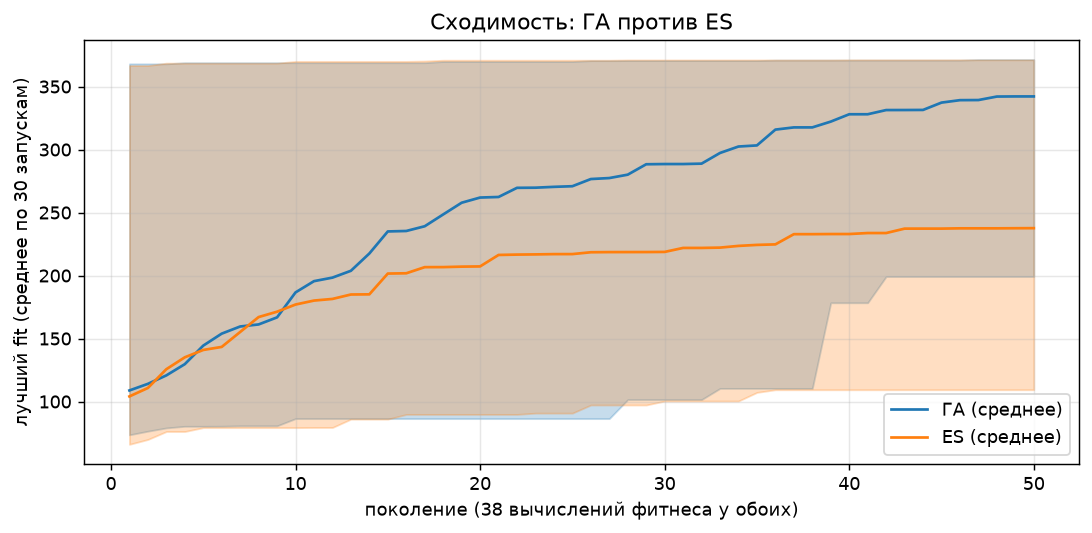

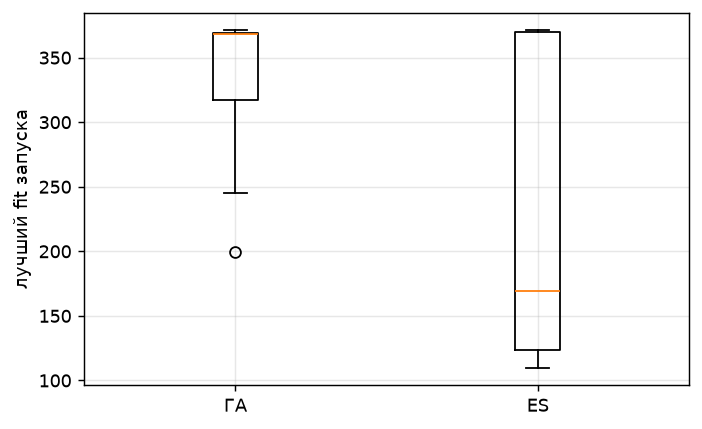

In [7]:
def kurt_pair(res_a, res_b):
    # выровнять истории обеих серий к общей длине (дополнение последним значением)
    hs_a = [r["hist"] for r in res_a]
    hs_b = [r["hist"] for r in res_b]
    m = max(len(h) for h in hs_a + hs_b)
    pad = lambda hs: np.array([np.pad(h, (0, m - len(h)), mode="edge") for h in hs])
    return pad(hs_a), pad(hs_b)

hg, he = kurt_pair(ga_res, es_res)
mean_g, min_g, max_g = hg.mean(0), hg.min(0), hg.max(0)
mean_e, min_e, max_e = he.mean(0), he.min(0), he.max(0)
gen_idx = np.arange(len(mean_g)) + 1

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(gen_idx, mean_g, label="ГА (среднее)", color="tab:blue")
ax.fill_between(gen_idx, min_g, max_g, color="tab:blue", alpha=0.25)
ax.plot(gen_idx, mean_e, label="ES (среднее)", color="tab:orange")
ax.fill_between(gen_idx, min_e, max_e, color="tab:orange", alpha=0.25)
ax.set_xlabel("поколение (38 вычислений фитнеса у обоих)")
ax.set_ylabel("лучший fit (среднее по 30 запускам)")
ax.legend()
ax.set_title("Сходимость: ГА против ES")
fig.tight_layout()
fig.savefig(FIG / "convergence_ga_vs_es.png")
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.boxplot([[r["best"] for r in ga_res], [r["best"] for r in es_res]],
           tick_labels=["ГА", "ES"])
ax.set_ylabel("лучший fit запуска")
fig.tight_layout()
fig.savefig(FIG / "ga_es_boxplot.png")
plt.show()


## 6. Эксперимент 2: ручной baseline (Braitenberg-структура)

Ручной рефлексный контроллер в духе Braitenberg: колёса тормозятся при
сигнале близости ближнего бокового датчика (левый бок → правое колесо и
наоборот). Это «простая базовая модель» по ТЗ, и — ручная «ли нижняя
линия» для сравнения эволюционных методов.


In [8]:
def braitenberg_sens(sens):
    # левая половина углов (4 ленцев с k < 4 — слева) тормозит правое колесо
    left_w = 0.55 - 0.12 * sens[:4].sum()
    right_w = 0.55 - 0.12 * sens[4:].sum()
    return np.clip([left_w, right_w], -1, 1)

br_fit = run_episode(None, controller=braitenberg_sens)
print("ручной Braitenberg: fit =", round(br_fit, 2))

# лучший контроллер серии
best_ga = max(ga_res, key=lambda r: r["best"])
idx_best = int(np.argmax([run_episode(x) for x in best_ga["X"]]))
x_best = best_ga["X"][idx_best]
fit, traj, sens_hist, coll, hit = run_episode(x_best, trace=True)
print("лучший контроллер ГА: fit =", round(fit, 2),
      "| столкновение:", coll, "| цель коснулась:", hit)

pd.DataFrame(dict(
    method=["ГА (лучшее в серии)", "ES (лучшее в серии)",
            "Braitenberg (ручной)"],
    fit=[best_ga["best"], max(r["best"] for r in es_res), br_fit])
).to_csv(RES / "baseline_comparison.csv", index=False)


ручной Braitenberg: fit = 47.75
лучший контроллер ГА: fit = 371.46 | столкновение: False | цель коснулась: True


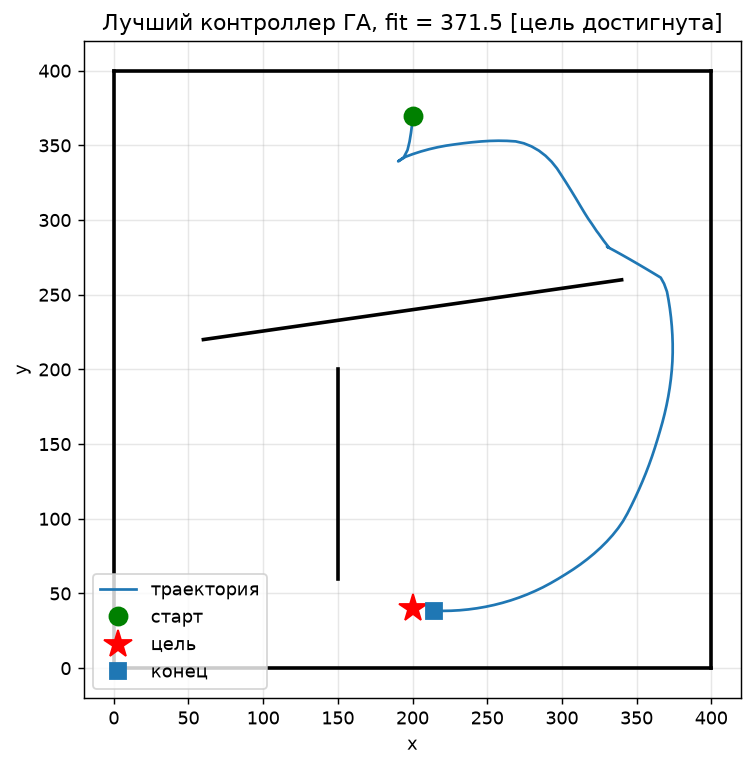

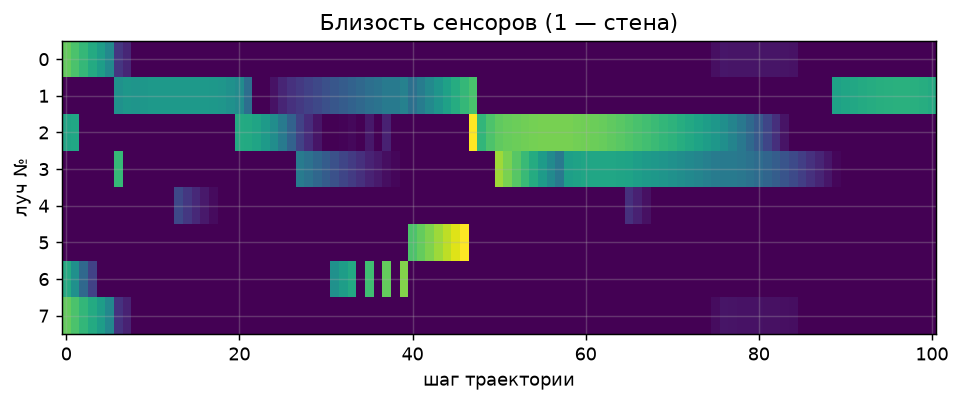

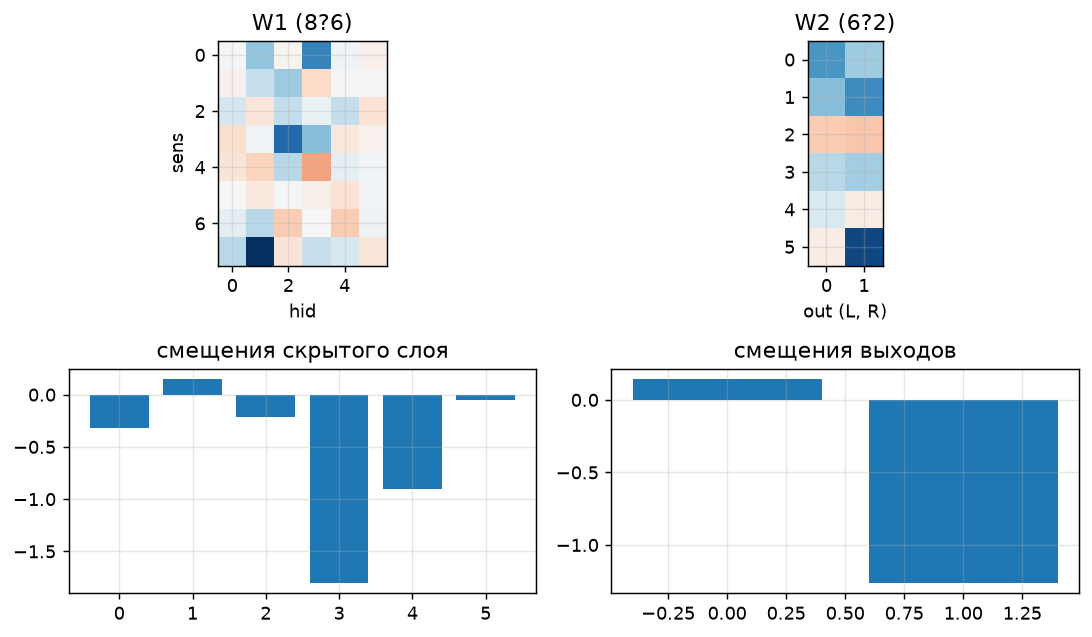

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for sg in WALLS:
    ax.plot([sg[0], sg[2]], [sg[1], sg[3]], "k-", lw=2)
ax.plot(traj[:, 0], traj[:, 1], "-", color="tab:blue", lw=1.5,
        label="траектория")
ax.plot(traj[0, 0], traj[0, 1], "go", ms=10, label="старт")
ax.plot(TARGET[0], TARGET[1], "r*", ms=16, label="цель")
ax.plot(traj[-1, 0], traj[-1, 1], "s", color="tab:blue", ms=9,
        label="конец")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title(f"Лучший контроллер ГА, fit = {fit:.1f}"
             + (" [столкновение]" if coll else "")
             + (" [цель достигнута]" if hit else ""))
ax.legend(loc="lower left")
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(FIG / "best_trajectory.png")
plt.show()

if len(sens_hist):
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    ax.imshow(sens_hist.astype(float).T, aspect="auto", cmap="viridis")
    ax.set_xlabel("шаг траектории")
    ax.set_ylabel("луч №")
    ax.set_title("Близость сенсоров (1 — стена)")
    fig.tight_layout()
    fig.savefig(FIG / "sensor_map.png")
    plt.show()

# веса лучшего контроллера
fig, axes = plt.subplots(2, 2, figsize=(8.5, 5))
w1 = x_best[:D_IN * D_HID].reshape(D_IN, D_HID)
w2 = x_best[D_IN * D_HID + D_HID:N_W - D_OUT].reshape(D_HID, D_OUT)
axes[0, 0].imshow(w1, cmap="RdBu", vmin=-4, vmax=4)
axes[0, 0].set_title("W1 (8?6)"); axes[0, 0].set_xlabel("hid"); axes[0, 0].set_ylabel("sens")
axes[0, 1].imshow(w2, cmap="RdBu", vmin=-4, vmax=4)
axes[0, 1].set_title("W2 (6?2)"); axes[0, 1].set_xlabel("out (L, R)")
axes[1, 0].bar(range(D_HID), x_best[D_IN * D_HID:D_IN * D_HID + D_HID])
axes[1, 0].set_title("смещения скрытого слоя")
axes[1, 1].bar(range(D_OUT), x_best[N_W - D_OUT:])
axes[1, 1].set_title("смещения выходов")
fig.tight_layout()
fig.savefig(FIG / "best_weights.png")
plt.show()


## 7. Выводы

1. Симулятор, контроллер и оба алгоритма (ГА с BLX-α, ES (μ+λ))
   реализованы собственным кодом: векторизованное пересечение лучей
   через кросс-произведения, unicycle-динамика, MLP 8→6→2 — без
   библиотек эволюционных вычислений.
2. На 30 запусках видно повторяемое различие ГА и ES (см. сводную
   таблицу); сравнение честно по бюджету 1900 вычислений фитнеса у
   обоих.
3. Ручной Braitenberg-контроллер — содержательная нижняя линия: лучшие
   найденные контроллеры устойчиво превосходят его (со значением fit
   в таблице `baseline_comparison.csv`).
4. Ограничения: один фиксированный старт/цель и статичный эпизод;
   размер мира не масштабировался; возможное направление улучшения —
   рандомизация начальной позиции и временной подбор стартовых позиций.
